# Imports

In [2]:
import os
import json
import time
import itertools
import random

from pathlib import Path

from tqdm.auto import tqdm

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

from IPython.display import display

# Hyper Parameters

In [3]:
# ============================================================
# HYPERPARAMETER SEARCH SPACE
# ============================================================

# Last 3 values from the original logarithmic weight-decay grid
WEIGHT_DECAYS = np.geomspace(1e-4, 0.2, num=6)[-3:].tolist()

# Focus on narrow vs. wide networks
HIDDEN_WIDTHS = [12, 512]

# Focus on higher label-noise conditions
LABEL_NOISE_PERCENTAGES = [15, 25]


# ============================================================
# TRAINING PARAMETERS
# ============================================================

EPOCHS = 10_000
BATCH_SIZE = 512
LEARNING_RATE = 1e-3

OPTIMIZER = "AdamW"

# Dataset
MODULUS = 97
TRAIN_FRACTION = 0.70


# ============================================================
# RANDOM SEEDS
# ============================================================

# Fixed dataset seed to ensure identical training/test splits
# and label corruption across all model seeds
DATA_SEED = 42

# Five independent model initialization seeds
MODEL_SEEDS = [42, 43, 44, 45, 46]


# ============================================================
# EVALUATION & CHECKPOINTS
# ============================================================

EVAL_EVERY = 50
CHECKPOINT_EVERY = 1000

TRAIN_ACCURACY_THRESHOLD = 0.99
GROKKING_MIN_DELAY = 200

SAVE_MODELS = True


# ============================================================
# EXPERIMENT SELECTION
# ============================================================

# None = all configurations, each trained with all MODEL_SEEDS
# Example: [0, 1, 2] = only these configurations
RUN_INDICES = None


# ============================================================
# DIRECTORIES
# ============================================================

OUT_DIR = Path("grokking_experiments2")

MODELS_DIR = OUT_DIR / "models"
DATASET_DIR = OUT_DIR / "datasets"

# Subdirectory name used for each model's seed runs
SEEDS_SUBDIR = "seeds"

OUT_DIR.mkdir(parents=True, exist_ok=True)
DATASET_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

CONFIG_FILE = OUT_DIR / "configurations.json"


# ============================================================
# MODEL TRAINING VISUALIZATION
# ============================================================

SHOW_PLOTS = False
SAVE_PLOTS = True


# ============================================================
# HARDWARE
# ============================================================

DEVICE = torch.device(
    "cuda:0" if torch.cuda.is_available() else "cpu"
)

print(f"Device: {DEVICE}")


# ============================================================
# EXPERIMENT SUMMARY
# ============================================================

NUM_CONFIGURATIONS = (
    len(WEIGHT_DECAYS)
    * len(HIDDEN_WIDTHS)
    * len(LABEL_NOISE_PERCENTAGES)
)

NUM_TRAINING_RUNS = (
    NUM_CONFIGURATIONS * len(MODEL_SEEDS)
)

print(f"Weight decay values: {WEIGHT_DECAYS}")
print(f"Network widths: {HIDDEN_WIDTHS}")
print(f"Label noise: {LABEL_NOISE_PERCENTAGES}")
print(f"Model seeds: {MODEL_SEEDS}")

print(f"\nConfigurations: {NUM_CONFIGURATIONS}")
print(f"Seeds per configuration: {len(MODEL_SEEDS)}")
print(f"Total training runs: {NUM_TRAINING_RUNS}")

Device: cuda:0
Weight decay values: [0.009563524997900363, 0.04373448295773111, 0.2]
Network widths: [12, 512]
Label noise: [15, 25]
Model seeds: [42, 43, 44, 45, 46]

Configurations: 12
Seeds per configuration: 5
Total training runs: 60


# Pre-defined training essentials

##### Configuration.json - json used to store all model possible configurations(combinations), it's used by the code to then grab a different model for training

##### Datasets - generates |LABEL_NOISE| ammount of datasets labeled as datset_X.csv where X is in LABEL_NOISE and is the % of noise

In [4]:

# ============================================================
# CONFIGURATIONS.JSON
# ============================================================

configurations = []

# Generate all combinations of weight decay, width, and noise
for index, (wd, width, noise) in enumerate(
    itertools.product(
        WEIGHT_DECAYS,
        HIDDEN_WIDTHS,
        LABEL_NOISE_PERCENTAGES
    )
):
    configurations.append({
        "index": index,
        "weightDecay": float(wd),
        "hiddenWidth": int(width),
        "labelNoise": int(noise)
    })


# Save configurations without overwriting incompatible experiments
if CONFIG_FILE.exists():

    with open(CONFIG_FILE, "r") as f:
        existing_configs = json.load(f)

    if existing_configs != configurations:
        raise ValueError(
            "Existing configurations.json does not match "
            "the current hyperparameters. "
            "Use a new output directory to avoid mixing experiments."
        )

    print("Existing configurations.json verified.")

else:

    with open(CONFIG_FILE, "w") as f:
        json.dump(configurations, f, indent=4)

    print(f"Saved configurations: {CONFIG_FILE}")

print(f"Total configurations: {len(configurations)}")
print(f"Model seeds per configuration: {len(MODEL_SEEDS)}")
print(f"Total training runs: {len(configurations) * len(MODEL_SEEDS)}")


# ============================================================
# GENERATE MODULAR ADDITION DATASET
# ============================================================

X = []
y = []

for a in range(MODULUS):
    for b in range(MODULUS):
        X.append([a, b])
        y.append((a + b) % MODULUS)

X = np.array(X, dtype=np.int64)
y = np.array(y, dtype=np.int64)


# ============================================================
# TRAIN / TEST SPLIT
# ============================================================

# Keep the same split for every model and every model seed
rng = np.random.default_rng(DATA_SEED)

random_indices_list = rng.permutation(len(X))

train_size = int(len(X) * TRAIN_FRACTION)

train_indices = random_indices_list[:train_size]
test_indices = random_indices_list[train_size:]

X_train = X[train_indices]
y_train_clean = y[train_indices]

X_test = X[test_indices]
y_test = y[test_indices]

print(f"\nTotal examples: {len(X):,}")
print(f"Training examples: {len(X_train):,}")
print(f"Test examples: {len(X_test):,}")


# ============================================================
# GENERATE NOISY DATASETS
# ============================================================

# Fixed noise generation across all model seeds
noise_rng = np.random.default_rng(DATA_SEED + 1)

noise_order = noise_rng.permutation(train_size)

# Nonzero offsets ensure corrupted labels are always incorrect
noise_offsets = noise_rng.integers(
    1,
    MODULUS,
    size=train_size
)


for noise in LABEL_NOISE_PERCENTAGES:

    # Start from the original clean training labels
    y_train = y_train_clean.copy()

    # Number of training labels to corrupt
    n_corrupt = round(train_size * noise / 100)

    corrupt_indices = noise_order[:n_corrupt]

    # Corrupt only training labels
    y_train[corrupt_indices] = (
        y_train[corrupt_indices]
        + noise_offsets[corrupt_indices]
    ) % MODULUS

    # Combine training and test examples
    dataset_df = pd.DataFrame({
        "a": np.concatenate((X_train[:, 0], X_test[:, 0])),
        "b": np.concatenate((X_train[:, 1], X_test[:, 1])),
        "label": np.concatenate((y_train, y_test)),
        "cleanLabel": np.concatenate((y_train_clean, y_test)),
        "split": (
            ["train"] * train_size
            + ["test"] * len(X_test)
        )
    })

    dataset_path = DATASET_DIR / f"dataset_{noise}.csv"

    # Avoid accidentally replacing an existing dataset
    if dataset_path.exists():

        existing_df = pd.read_csv(dataset_path)

        if not existing_df.equals(dataset_df):
            raise ValueError(
                f"Dataset {noise}% differs from the "
                "existing saved dataset."
            )

        print(
            f"Verified: {dataset_path.name} | "
            f"Noise: {noise}% | "
            f"Corrupted: {n_corrupt}/{train_size}"
        )

    else:

        dataset_df.to_csv(dataset_path, index=False)

        print(
            f"Saved: {dataset_path.name} | "
            f"Noise: {noise}% | "
            f"Corrupted: {n_corrupt}/{train_size}"
        )


print(
    f"\nPrepared {len(LABEL_NOISE_PERCENTAGES)} datasets."
)


# ============================================================
# LOAD DATASETS INTO PYTORCH
# ============================================================

print(f"\nLoading datasets onto {DEVICE}...")

DATASETS = {}

for noise in LABEL_NOISE_PERCENTAGES:

    dataset_path = DATASET_DIR / f"dataset_{noise}.csv"

    df = pd.read_csv(dataset_path)

    train_df = df[df["split"] == "train"]
    test_df = df[df["split"] == "test"]

    DATASETS[noise] = {

        "X_train": torch.tensor(
            train_df[["a", "b"]].to_numpy(),
            dtype=torch.long,
            device=DEVICE
        ),

        "y_train": torch.tensor(
            train_df["label"].to_numpy(),
            dtype=torch.long,
            device=DEVICE
        ),

        "y_train_clean": torch.tensor(
            train_df["cleanLabel"].to_numpy(),
            dtype=torch.long,
            device=DEVICE
        ),

        "X_test": torch.tensor(
            test_df[["a", "b"]].to_numpy(),
            dtype=torch.long,
            device=DEVICE
        ),

        "y_test": torch.tensor(
            test_df["cleanLabel"].to_numpy(),
            dtype=torch.long,
            device=DEVICE
        )
    }

    print(
        f"Loaded: Dataset {noise:2d}% | "
        f"Train: {len(train_df):,} | "
        f"Test: {len(test_df):,} | "
        f"Device: {DEVICE}"
    )


print("\nAll datasets loaded successfully.")


Saved configurations: grokking_experiments2/configurations.json
Total configurations: 12
Model seeds per configuration: 5
Total training runs: 60

Total examples: 9,409
Training examples: 6,586
Test examples: 2,823
Saved: dataset_15.csv | Noise: 15% | Corrupted: 988/6586
Saved: dataset_25.csv | Noise: 25% | Corrupted: 1646/6586

Prepared 2 datasets.

Loading datasets onto cuda:0...
Loaded: Dataset 15% | Train: 6,586 | Test: 2,823 | Device: cuda:0
Loaded: Dataset 25% | Train: 6,586 | Test: 2,823 | Device: cuda:0

All datasets loaded successfully.


# Model Architecture

input(2) ->

-> shared embedding(MODULUS * hidden_dim) ->

-> embedding(2 * hidden_dim) ->

-> concat(2 * hidden_dim) ->

-> hidden1(2 * hidden_dim) -> Relu ->

-> hidden2(hidden_dim) -> Relu ->

-> Output(97) -> ArgMax 

In [5]:
class GrokkingMLP(nn.Module):

    def __init__(self, hidden_dim):
        super().__init__()

        self.embedding = nn.Embedding(MODULUS, hidden_dim)
        self.mlp = nn.Sequential(
            nn.Linear(2 * hidden_dim, 4 * hidden_dim),
            nn.ReLU(),
            nn.Linear(4 * hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, MODULUS)
        )

    def forward(self, x):

        # x shape (batch_size, 2)
        x = self.embedding(x)

        # Shape: (batch_size, 2*d)
        x = x.flatten(start_dim=1)

        # Output shape: (batch_size, 97)
        return self.mlp(x)

def count_parameters(model):
    return sum(
        parameter.numel()
        for parameter in model.parameters()
        if parameter.requires_grad
    )

# Evaluation

In [6]:
# ============================================================
# MODEL EVALUATION
# ============================================================

import torch.nn.functional as F


@torch.inference_mode()
def evaluate_model(model, dataset, batch_size=BATCH_SIZE):

    # Remember the original model mode
    was_training = model.training
    model.eval()

    # Dataset
    X_train = dataset["X_train"]
    y_train = dataset["y_train"]
    y_train_clean = dataset["y_train_clean"]

    X_test = dataset["X_test"]
    y_test = dataset["y_test"]

    # ========================================================
    # 1. TRAINING METRICS
    # ========================================================

    total_train_loss = 0.0
    total_clean_train_loss = 0.0

    correct_train = 0
    correct_clean_train = 0

    # ========================================================
    # 2. TEST METRICS
    # ========================================================

    total_test_loss = 0.0
    correct_test = 0

    try:

        # ----------------------------------------------------
        # EVALUATE TRAINING DATA
        # ----------------------------------------------------

        for start in range(0, len(X_train), batch_size):

            end = start + batch_size

            outputs = model(X_train[start:end])

            noisy_labels = y_train[start:end]
            clean_labels = y_train_clean[start:end]

            # Loss against noisy training labels
            total_train_loss += F.cross_entropy(
                outputs,
                noisy_labels,
                reduction="sum"
            ).item()

            # Loss against mathematically correct labels
            total_clean_train_loss += F.cross_entropy(
                outputs,
                clean_labels,
                reduction="sum"
            ).item()

            # Predicted classes
            predictions = outputs.argmax(dim=1)

            correct_train += (
                predictions == noisy_labels
            ).sum().item()

            correct_clean_train += (
                predictions == clean_labels
            ).sum().item()

        # ----------------------------------------------------
        # EVALUATE TEST DATA
        # ----------------------------------------------------

        for start in range(0, len(X_test), batch_size):

            end = start + batch_size

            outputs = model(X_test[start:end])

            labels = y_test[start:end]

            # Test loss
            total_test_loss += F.cross_entropy(
                outputs,
                labels,
                reduction="sum"
            ).item()

            # Test accuracy
            predictions = outputs.argmax(dim=1)

            correct_test += (
                predictions == labels
            ).sum().item()

    finally:

        # Restore original model mode
        model.train(was_training)

    # ========================================================
    # 3. CALCULATE AVERAGE LOSSES
    # ========================================================

    train_loss = total_train_loss / len(X_train)

    clean_train_loss = (
        total_clean_train_loss / len(X_train)
    )

    test_loss = total_test_loss / len(X_test)

    # ========================================================
    # 4. CALCULATE ACCURACIES
    # ========================================================

    train_accuracy = correct_train / len(X_train)

    clean_train_accuracy = (
        correct_clean_train / len(X_train)
    )

    test_accuracy = correct_test / len(X_test)

    # ========================================================
    # 5. RETURN RESULTS
    # ========================================================

    return {
        "trainLoss": train_loss,
        "cleanTrainLoss": clean_train_loss,
        "testLoss": test_loss,

        "trainAccuracy": train_accuracy,
        "cleanTrainAccuracy": clean_train_accuracy,
        "testAccuracy": test_accuracy
    }

# Grokking detection

#### criteria:  
1. rain convergence: Accuracy ≈ 100%.  
2. Validation convergence: Accuracy ≥ 1 − noise (e.g., 85%).  
3. Minimum delay: Δt= t_val − t_train ≥ T₁.
4. Time limit: t_val ≤ T₂.
5. Color: Δt(green = faster, red = slower).
6. Missing point: No grokking detected by T₂.

#### differences to Experiment 1:  
- Added a fixed 95% clean test accuracy threshold, independent of label noise
- Records generalizationEpoch - the first evaluated epoch reaching 95% test accuracy
- Records generalized - whether the model reached this threshold.
- Does not require memorization of noisy training labels


In [7]:
# ============================================================
# GROKKING & GENERALIZATION DETECTION
# ============================================================

# Independent of label noise and training convergence
GENERALIZATION_ACCURACY_THRESHOLD = 0.95


def detect_grokking(
    history,
    label_noise,
    train_threshold=TRAIN_ACCURACY_THRESHOLD,
    min_delay=GROKKING_MIN_DELAY,
    max_epoch=EPOCHS,
    generalization_threshold=GENERALIZATION_ACCURACY_THRESHOLD
):

    df = pd.DataFrame(history).copy()

    required_columns = [
        "epoch",
        "trainAccuracy",
        "testAccuracy"
    ]

    if not all(col in df.columns for col in required_columns):
        raise ValueError(
            "Training history is missing required columns."
        )

    # Sort by epoch and ignore measurements beyond T2
    df = df.sort_values("epoch")
    df = df[df["epoch"] <= max_epoch]
    df = df.drop_duplicates("epoch", keep="last")

    # ========================================================
    # HELPER: FIND FIRST CONVERGENCE EPOCH
    # ========================================================

    def first_convergence_epoch(column, threshold):

        converged = df[df[column] >= threshold]

        if converged.empty:
            return None

        return int(converged.iloc[0]["epoch"])


    # ========================================================
    # 1. ORIGINAL GROKKING CRITERIA
    # ========================================================

    # Training convergence: noisy training accuracy >= 99%
    t_train = first_convergence_epoch(
        "trainAccuracy",
        train_threshold
    )

    # Test convergence: accuracy >= 1 - noise
    test_threshold = 1 - (label_noise / 100)

    t_val = first_convergence_epoch(
        "testAccuracy",
        test_threshold
    )


    # ========================================================
    # 2. GROKKING DELAY
    # ========================================================

    delay = None

    if t_train is not None and t_val is not None:
        delay = t_val - t_train


    # ========================================================
    # 3. ORIGINAL GROKKING CLASSIFICATION
    # ========================================================

    within_time_limit = (
        t_val is not None
        and t_val <= max_epoch
    )

    grokked = (
        t_train is not None
        and within_time_limit
        and delay >= min_delay
    )


    # ========================================================
    # 4. INDEPENDENT GENERALIZATION DETECTION
    # ========================================================

    # First epoch where clean test accuracy reaches 95%.
    # Does NOT require memorizing noisy training labels.

    t_generalization = first_convergence_epoch(
        "testAccuracy",
        generalization_threshold
    )

    generalized = t_generalization is not None


    # ========================================================
    # 5. RETURN RESULTS
    # ========================================================

    return {

        # Original Grokking detection
        "trainConvergenceEpoch": t_train,
        "testConvergenceEpoch": t_val,
        "grokkingDelay": delay,
        "grokked": bool(grokked),

        "trainThreshold": train_threshold,
        "testThreshold": test_threshold,

        # Independent generalization detection
        "generalizationEpoch": t_generalization,
        "generalized": bool(generalized),
        "generalizationThreshold": generalization_threshold
    }

# Model training function  

Main difference from Experimet 1 is that now train_model(config) will not train every seed in MODEL_SEEDS and calc the avrages after that

In [8]:
# ============================================================
# MULTI-SEED MODEL TRAINING
# ============================================================

METRIC_COLUMNS = [
    "trainLoss",
    "cleanTrainLoss",
    "testLoss",
    "trainAccuracy",
    "cleanTrainAccuracy",
    "testAccuracy"
]


# ============================================================
# HELPERS: SAFE FILE SAVING
# ============================================================

def save_json_atomic(data, path):

    temp_path = path.with_name(path.name + ".tmp")

    with open(temp_path, "w") as f:
        json.dump(data, f, indent=4)

    temp_path.replace(path)


def save_csv_atomic(df, path):

    temp_path = path.with_name(path.name + ".tmp")

    df.to_csv(temp_path, index=False)

    temp_path.replace(path)


def get_training_settings(seed):

    # Used to detect incompatible saved runs
    return {
        "modelSeed": int(seed),
        "dataSeed": int(DATA_SEED),
        "epochs": int(EPOCHS),
        "batchSize": int(BATCH_SIZE),
        "learningRate": float(LEARNING_RATE),
        "optimizer": OPTIMIZER,
        "evalEvery": int(EVAL_EVERY),
        "checkpointEvery": int(CHECKPOINT_EVERY),
        "trainFraction": float(TRAIN_FRACTION),
        "modulus": int(MODULUS),
        "trainThreshold": float(TRAIN_ACCURACY_THRESHOLD),
        "grokkingMinDelay": int(GROKKING_MIN_DELAY),
        "generalizationThreshold": float(
            GENERALIZATION_ACCURACY_THRESHOLD
        )
    }


# ============================================================
# 1. TRAIN ONE MODEL WITH ONE SEED
# ============================================================

def train_model_seed(config, seed):

    index = int(config["index"])
    weight_decay = float(config["weightDecay"])
    hidden_width = int(config["hiddenWidth"])
    label_noise = int(config["labelNoise"])
    seed = int(seed)

    # --------------------------------------------------------
    # DIRECTORIES
    # --------------------------------------------------------

    model_dir = MODELS_DIR / f"model_{index:03d}"

    seed_dir = (
        model_dir
        / SEEDS_SUBDIR
        / f"seed_{seed}"
    )

    seed_dir.mkdir(parents=True, exist_ok=True)

    checkpoint_path = seed_dir / "checkpoint.pt"
    model_path = seed_dir / "model.pt"
    history_path = seed_dir / "history.csv"
    summary_path = seed_dir / "summary.json"

    training_settings = get_training_settings(seed)

    # --------------------------------------------------------
    # SKIP COMPLETED SEED
    # --------------------------------------------------------

    if summary_path.exists():

        with open(summary_path, "r") as f:
            summary = json.load(f)

        if any(
            summary.get(k) != v
            for k, v in config.items()
        ):
            raise ValueError(
                f"Model {index:03d}, seed {seed}: "
                "configuration mismatch."
            )

        if summary.get("trainingSettings") != training_settings:
            raise ValueError(
                f"Model {index:03d}, seed {seed}: "
                "training settings mismatch."
            )

        if not history_path.exists():
            raise FileNotFoundError(
                f"Missing history for model {index:03d}, "
                f"seed {seed}."
            )

        if SAVE_MODELS and not model_path.exists():
            raise FileNotFoundError(
                f"Missing model weights for model "
                f"{index:03d}, seed {seed}."
            )

        print(
            f"Model {index:03d} | Seed {seed}: "
            "Already completed. Skipping."
        )

        return summary

    # --------------------------------------------------------
    # SELECT DATASET
    # --------------------------------------------------------

    dataset = DATASETS[label_noise]

    X_train = dataset["X_train"]
    y_train = dataset["y_train"]

    # --------------------------------------------------------
    # INITIALIZE RANDOM SEED
    # --------------------------------------------------------

    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    # --------------------------------------------------------
    # INITIALIZE MODEL
    # --------------------------------------------------------

    model = GrokkingMLP(
        hidden_dim=hidden_width
    ).to(DEVICE)

    # --------------------------------------------------------
    # OPTIMIZER AND LOSS
    # --------------------------------------------------------

    if OPTIMIZER.lower() != "adamw":
        raise ValueError(
            f"Unsupported optimizer: {OPTIMIZER}"
        )

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=weight_decay
    )

    loss_fn = nn.CrossEntropyLoss()

    # --------------------------------------------------------
    # TRAINING STATE
    # --------------------------------------------------------

    start_epoch = 1
    history = []
    elapsed_seconds = 0.0

    # --------------------------------------------------------
    # RESUME FROM CHECKPOINT
    # --------------------------------------------------------

    if checkpoint_path.exists():

        checkpoint = torch.load(
            checkpoint_path,
            map_location=DEVICE,
            weights_only=False
        )

        if checkpoint.get("config") != config:
            raise ValueError(
                f"Model {index:03d}, seed {seed}: "
                "checkpoint configuration mismatch."
            )

        if checkpoint.get("trainingSettings") != training_settings:
            raise ValueError(
                f"Model {index:03d}, seed {seed}: "
                "checkpoint training settings mismatch."
            )

        checkpoint_epoch = int(checkpoint["epoch"])

        if not 1 <= checkpoint_epoch <= EPOCHS:
            raise ValueError(
                f"Invalid checkpoint epoch: {checkpoint_epoch}"
            )

        model.load_state_dict(
            checkpoint["model_state_dict"]
        )

        optimizer.load_state_dict(
            checkpoint["optimizer_state_dict"]
        )

        start_epoch = checkpoint_epoch + 1

        history = checkpoint["history"]

        elapsed_seconds = checkpoint.get(
            "elapsedSeconds", 0.0
        )

        print(
            f"Model {index:03d} | Seed {seed}: "
            f"Resuming from epoch {start_epoch}"
        )

    # --------------------------------------------------------
    # TRAINING
    # --------------------------------------------------------

    print(
        f"\nTraining Model {index:03d} | "
        f"Seed={seed} | Width={hidden_width} | "
        f"WD={weight_decay:.6g} | Noise={label_noise}%"
    )

    start_time = time.time()

    for epoch in range(start_epoch, EPOCHS + 1):

        model.train()

        # Deterministic shuffling for this seed and epoch
        generator = torch.Generator().manual_seed(
            seed + epoch
        )

        shuffled_indices = torch.randperm(
            len(X_train),
            generator=generator
        ).to(DEVICE)

        # ----------------------------------------------------
        # MINI-BATCH TRAINING
        # ----------------------------------------------------

        for batch_indices in shuffled_indices.split(BATCH_SIZE):

            optimizer.zero_grad(set_to_none=True)

            outputs = model(
                X_train[batch_indices]
            )

            loss = loss_fn(
                outputs,
                y_train[batch_indices]
            )

            loss.backward()

            optimizer.step()

        # ----------------------------------------------------
        # EVALUATION
        # ----------------------------------------------------

        if (
            epoch == 1
            or epoch % EVAL_EVERY == 0
            or epoch == EPOCHS
        ):

            metrics = evaluate_model(
                model,
                dataset
            )

            history.append({
                "epoch": epoch,
                **metrics
            })

        # ----------------------------------------------------
        # CHECKPOINT
        # ----------------------------------------------------

        if epoch % CHECKPOINT_EVERY == 0:

            checkpoint = {
                "epoch": epoch,
                "config": config,
                "trainingSettings": training_settings,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "history": history,
                "elapsedSeconds": (
                    elapsed_seconds
                    + time.time() - start_time
                )
            }

            temp_path = (
                seed_dir / "checkpoint.tmp"
            )

            torch.save(
                checkpoint,
                temp_path
            )

            temp_path.replace(checkpoint_path)

        # ----------------------------------------------------
        # PROGRESS
        # ----------------------------------------------------

        if (
            epoch % 1000 == 0
            or epoch == EPOCHS
        ):

            latest = history[-1]

            print(
                f"Model {index:03d} | "
                f"Seed {seed} | "
                f"Epoch {epoch:5d}/{EPOCHS} | "
                f"Train: {latest['trainAccuracy']:.4f} | "
                f"Test: {latest['testAccuracy']:.4f}"
            )

    # --------------------------------------------------------
    # ENSURE FINAL EVALUATION EXISTS
    # --------------------------------------------------------

    # Also handles a checkpoint saved at the final epoch
    # before the previous run completed its summary.

    if not history or history[-1]["epoch"] != EPOCHS:

        metrics = evaluate_model(
            model,
            dataset
        )

        history.append({
            "epoch": EPOCHS,
            **metrics
        })

    # --------------------------------------------------------
    # GROKKING AND GENERALIZATION DETECTION
    # --------------------------------------------------------

    detection = detect_grokking(
        history=history,
        label_noise=label_noise
    )

    total_elapsed = (
        elapsed_seconds
        + time.time() - start_time
    )

    # --------------------------------------------------------
    # SAVE INDIVIDUAL SEED RESULTS
    # --------------------------------------------------------

    history_df = pd.DataFrame(history)

    if SAVE_MODELS:

        temp_model_path = (
            seed_dir / "model.tmp"
        )

        torch.save(
            model.state_dict(),
            temp_model_path
        )

        temp_model_path.replace(model_path)

    save_csv_atomic(
        history_df,
        history_path
    )

    summary = {
        **config,

        "modelSeed": seed,
        "trainingSettings": training_settings,

        "epochs": EPOCHS,
        "parameters": count_parameters(model),

        # Grokking + independent generalization
        **detection,

        # Final accuracy
        "finalTrainAccuracy": history[-1]["trainAccuracy"],
        "finalCleanTrainAccuracy": history[-1]["cleanTrainAccuracy"],
        "finalTestAccuracy": history[-1]["testAccuracy"],

        # Final loss
        "finalTrainLoss": history[-1]["trainLoss"],
        "finalCleanTrainLoss": history[-1]["cleanTrainLoss"],
        "finalTestLoss": history[-1]["testLoss"],

        "elapsedSeconds": total_elapsed
    }

    save_json_atomic(
        summary,
        summary_path
    )

    # Remove checkpoint only after saving the final results
    checkpoint_path.unlink(missing_ok=True)

    print(
        f"Completed Model {index:03d} | "
        f"Seed {seed} | "
        f"Grokked: {detection['grokked']} | "
        f"Generalized: {detection['generalized']} | "
        f"Test: {summary['finalTestAccuracy']:.4f}"
    )

    return summary


# ============================================================
# 2. AGGREGATE RESULTS ACROSS SEEDS
# ============================================================

def aggregate_model_results(config):

    index = int(config["index"])

    model_dir = MODELS_DIR / f"model_{index:03d}"

    seed_summaries = []
    seed_histories = []

    # --------------------------------------------------------
    # LOAD ALL SEED RESULTS
    # --------------------------------------------------------

    for seed in MODEL_SEEDS:

        seed_dir = (
            model_dir
            / SEEDS_SUBDIR
            / f"seed_{seed}"
        )

        summary_path = seed_dir / "summary.json"
        history_path = seed_dir / "history.csv"

        if not summary_path.exists() or not history_path.exists():
            raise FileNotFoundError(
                f"Model {index:03d}, seed {seed} "
                "has not completed."
            )

        with open(summary_path, "r") as f:
            summary = json.load(f)

        if any(
            summary.get(k) != v
            for k, v in config.items()
        ):
            raise ValueError(
                f"Model {index:03d}, seed {seed}: "
                "configuration mismatch during aggregation."
            )

        if summary.get("trainingSettings") != get_training_settings(seed):
            raise ValueError(
                f"Model {index:03d}, seed {seed}: "
                "training settings mismatch during aggregation."
            )

        history = pd.read_csv(history_path)

        if not set(METRIC_COLUMNS + ["epoch"]).issubset(
            history.columns
        ):
            raise ValueError(
                f"Model {index:03d}, seed {seed}: "
                "missing history metrics."
            )

        if (
            history.empty
            or int(history["epoch"].iloc[-1]) != EPOCHS
        ):
            raise ValueError(
                f"Model {index:03d}, seed {seed}: "
                "incomplete history."
            )

        seed_summaries.append(summary)
        seed_histories.append(history)

    # --------------------------------------------------------
    # CHECK EPOCH ALIGNMENT
    # --------------------------------------------------------

    epochs = seed_histories[0]["epoch"].to_numpy()

    for history in seed_histories[1:]:

        if not np.array_equal(
            epochs,
            history["epoch"].to_numpy()
        ):
            raise ValueError(
                f"Model {index:03d}: "
                "seed evaluation epochs do not match."
            )

    # --------------------------------------------------------
    # AVERAGE TRAINING HISTORY
    # --------------------------------------------------------

    averaged_history = pd.DataFrame({
        "epoch": epochs
    })

    for metric in METRIC_COLUMNS:

        values = np.stack([
            history[metric].to_numpy(dtype=float)
            for history in seed_histories
        ])

        averaged_history[f"{metric}Mean"] = (
            values.mean(axis=0)
        )

        averaged_history[f"{metric}Std"] = (
            values.std(axis=0, ddof=1)
            if len(MODEL_SEEDS) > 1
            else np.zeros(len(epochs))
        )

    save_csv_atomic(
        averaged_history,
        model_dir / "averaged_history.csv"
    )

    # --------------------------------------------------------
    # HELPER: AGGREGATE SCALAR METRIC
    # --------------------------------------------------------

    def aggregate_metric(key, successful_only=False):

        values = []

        for summary in seed_summaries:

            if successful_only and key == "grokkingDelay":
                if not summary["grokked"]:
                    continue

            value = summary.get(key)

            if value is not None:
                values.append(float(value))

        count = len(values)

        if count == 0:
            return {
                f"{key}Count": 0,
                f"{key}Mean": None,
                f"{key}Std": None
            }

        return {
            f"{key}Count": count,
            f"{key}Mean": float(np.mean(values)),
            f"{key}Std": (
                float(np.std(values, ddof=1))
                if count > 1
                else None
            )
        }

    # --------------------------------------------------------
    # GROKKING AND GENERALIZATION FREQUENCY
    # --------------------------------------------------------

    num_seeds = len(MODEL_SEEDS)

    grokking_count = sum(
        int(s["grokked"])
        for s in seed_summaries
    )

    generalization_count = sum(
        int(s["generalized"])
        for s in seed_summaries
    )

    # --------------------------------------------------------
    # PARENT MODEL SUMMARY
    # --------------------------------------------------------

    parent_summary = {
        **config,

        "epochs": EPOCHS,
        "parameters": seed_summaries[0]["parameters"],

        "modelSeeds": list(MODEL_SEEDS),
        "numSeeds": num_seeds,

        "grokkingCount": grokking_count,
        "grokkingRate": grokking_count / num_seeds,

        "generalizationCount": generalization_count,
        "generalizationRate": (
            generalization_count / num_seeds
        ),

        "trainThreshold": TRAIN_ACCURACY_THRESHOLD,
        "testThreshold": (
            1 - config["labelNoise"] / 100
        ),
        "generalizationThreshold": (
            GENERALIZATION_ACCURACY_THRESHOLD
        ),

        "elapsedSecondsTotal": sum(
            s["elapsedSeconds"]
            for s in seed_summaries
        )
    }

    # --------------------------------------------------------
    # FINAL ACCURACY AND LOSS: MEAN + STD
    # --------------------------------------------------------

    final_metrics = [
        "finalTrainAccuracy",
        "finalCleanTrainAccuracy",
        "finalTestAccuracy",
        "finalTrainLoss",
        "finalCleanTrainLoss",
        "finalTestLoss"
    ]

    for metric in final_metrics:

        parent_summary.update(
            aggregate_metric(metric)
        )

    # --------------------------------------------------------
    # CONVERGENCE EPOCHS: MEAN + STD
    # --------------------------------------------------------

    convergence_metrics = [
        "trainConvergenceEpoch",
        "testConvergenceEpoch",
        "generalizationEpoch"
    ]

    for metric in convergence_metrics:

        parent_summary.update(
            aggregate_metric(metric)
        )

    # Only average Grokking delays for runs
    # that actually satisfied the Grokking criteria.
    parent_summary.update(
        aggregate_metric(
            "grokkingDelay",
            successful_only=True
        )
    )

    # --------------------------------------------------------
    # SAVE PARENT SUMMARY
    # --------------------------------------------------------

    save_json_atomic(
        parent_summary,
        model_dir / "summary.json"
    )

    print(
        f"\nModel {index:03d} aggregation completed | "
        f"Grokking: {grokking_count}/{num_seeds} | "
        f"Generalization: {generalization_count}/{num_seeds} | "
        f"Mean test accuracy: "
        f"{parent_summary['finalTestAccuracyMean']:.4f}"
    )

    return parent_summary


# ============================================================
# 3. TRAIN ALL SEEDS FOR ONE CONFIGURATION
# ============================================================

def train_model(config):

    index = int(config["index"])

    if not MODEL_SEEDS:
        raise ValueError("MODEL_SEEDS cannot be empty.")

    if len(MODEL_SEEDS) != len(set(MODEL_SEEDS)):
        raise ValueError("Duplicate model seeds detected.")

    print("\n" + "=" * 65)
    print(f"MODEL {index:03d} — MULTI-SEED TRAINING")
    print("=" * 65)

    # Train or resume each seed independently
    for seed in MODEL_SEEDS:

        train_model_seed(
            config=config,
            seed=seed
        )

    # Aggregate only after all seeds have completed
    return aggregate_model_results(config)

# Visualization

In [9]:
# ============================================================
# MODEL TRAINING VISUALIZATION — EXPERIMENT 2
# ============================================================

def plot_model_results(model_index, show=SHOW_PLOTS):

    model_dir = MODELS_DIR / f"model_{model_index:03d}"

    # ========================================================
    # 1. HELPER: CREATE A FIGURE
    # ========================================================

    def create_figure(
        history,
        summary,
        figure_path,
        averaged=False,
        display_figure=False
    ):

        history = history.sort_values("epoch")

        epochs = history["epoch"].to_numpy(dtype=float)

        width = summary["hiddenWidth"]
        wd = summary["weightDecay"]
        noise = summary["labelNoise"]

        train_threshold = summary["trainThreshold"]
        test_threshold = summary["testThreshold"]
        generalization_threshold = summary["generalizationThreshold"]

        # ----------------------------------------------------
        # IDENTIFY CONVERGENCE EPOCHS
        # ----------------------------------------------------

        if averaged:

            t_train = summary.get("trainConvergenceEpochMean")
            t_val = summary.get("testConvergenceEpochMean")
            t_gen = summary.get("generalizationEpochMean")

            subtitle = (
                f"Mean ± SD across {summary['numSeeds']} seeds | "
                f"Grokking: {summary['grokkingCount']}/{summary['numSeeds']} | "
                f"Generalization: {summary['generalizationCount']}/{summary['numSeeds']}"
            )

        else:

            t_train = summary.get("trainConvergenceEpoch")
            t_val = summary.get("testConvergenceEpoch")
            t_gen = summary.get("generalizationEpoch")

            subtitle = (
                f"Seed: {summary['modelSeed']} | "
                f"Grokked: {summary['grokked']} | "
                f"Generalized: {summary['generalized']}"
            )

        # ----------------------------------------------------
        # CREATE FIGURE
        # ----------------------------------------------------

        fig, axes = plt.subplots(
            2, 2,
            figsize=(18, 11),
            constrained_layout=True
        )

        fig.suptitle(
            f"Model {model_index:03d} | "
            f"Width={width} | "
            f"WD={wd:.6g} | "
            f"Noise={noise}%\n"
            f"{subtitle}",
            fontsize=14,
            fontweight="bold"
        )

        # ====================================================
        # 2. DEFINE CURVES
        # ====================================================

        accuracy_curves = [
            ("trainAccuracy", "Train (Noisy)", "tab:blue"),
            ("cleanTrainAccuracy", "Train (Clean)", "tab:orange"),
            ("testAccuracy", "Test", "tab:green")
        ]

        loss_curves = [
            ("trainLoss", "Train (Noisy)", "tab:blue"),
            ("cleanTrainLoss", "Train (Clean)", "tab:orange"),
            ("testLoss", "Test", "tab:green")
        ]

        # ====================================================
        # 3. HELPER: PLOT METRIC CURVES
        # ====================================================

        def plot_curves(ax, curves, is_loss=False):

            for metric, label, color in curves:

                # Average uses Mean/Std column names
                column = (
                    f"{metric}Mean"
                    if averaged
                    else metric
                )

                if column not in history.columns:
                    raise ValueError(
                        f"Missing metric: {column}"
                    )

                values = history[column].to_numpy(
                    dtype=float
                )

                valid = np.isfinite(values)

                if is_loss:
                    plotted_values = np.maximum(
                        values[valid],
                        1e-8
                    )
                else:
                    plotted_values = values[valid]

                ax.plot(
                    epochs[valid],
                    plotted_values,
                    label=label,
                    color=color,
                    linewidth=2
                )

                # --------------------------------------------
                # STANDARD DEVIATION SHADING
                # --------------------------------------------

                if averaged:

                    std_column = f"{metric}Std"

                    if std_column not in history.columns:
                        raise ValueError(
                            f"Missing standard deviation: {std_column}"
                        )

                    std = history[std_column].to_numpy(
                        dtype=float
                    )

                    lower = values - std
                    upper = values + std

                    if is_loss:

                        lower = np.maximum(lower, 1e-8)
                        upper = np.maximum(upper, 1e-8)

                    else:

                        lower = np.clip(lower, 0, 1)
                        upper = np.clip(upper, 0, 1)

                    band_valid = (
                        valid
                        & np.isfinite(lower)
                        & np.isfinite(upper)
                    )

                    ax.fill_between(
                        epochs[band_valid],
                        lower[band_valid],
                        upper[band_valid],
                        color=color,
                        alpha=0.18
                    )

            if is_loss:
                ax.set_yscale("log")
                ax.set_ylabel("Cross-Entropy Loss (log scale)")
            else:
                ax.set_ylim(0, 1.05)
                ax.set_ylabel("Accuracy")

            ax.set_xlabel("Epoch")

            ax.grid(
                True,
                which="both",
                alpha=0.3
            )

        # ====================================================
        # 4. HELPER: CONVERGENCE MARKERS
        # ====================================================

        def add_convergence_markers(ax, accuracy=False):

            # Training convergence
            if t_train is not None:

                ax.axvline(
                    t_train,
                    color="tab:blue",
                    linestyle=":",
                    alpha=0.7,
                    label="Train convergence"
                    if accuracy else None
                )

            # Original test convergence (1 - noise)
            if t_val is not None:

                ax.axvline(
                    t_val,
                    color="tab:green",
                    linestyle=":",
                    alpha=0.7,
                    label="Test convergence"
                    if accuracy else None
                )

            # New independent generalization (95%)
            if t_gen is not None:

                ax.axvline(
                    t_gen,
                    color="purple",
                    linestyle="-.",
                    alpha=0.8,
                    label="95% generalization"
                    if accuracy else None
                )

        # ====================================================
        # 5. HELPER: ACCURACY THRESHOLDS
        # ====================================================

        def add_accuracy_thresholds(ax):

            ax.axhline(
                train_threshold,
                color="gray",
                linestyle="--",
                alpha=0.6,
                label=f"Train threshold ({train_threshold:.0%})"
            )

            ax.axhline(
                test_threshold,
                color="tab:green",
                linestyle="--",
                alpha=0.6,
                label=f"Test threshold ({test_threshold:.0%})"
            )

            ax.axhline(
                generalization_threshold,
                color="purple",
                linestyle="--",
                alpha=0.6,
                label=f"Generalization ({generalization_threshold:.0%})"
            )

        # ====================================================
        # 6. FULL ACCURACY HISTORY
        # ====================================================

        ax = axes[0, 0]

        plot_curves(
            ax,
            accuracy_curves
        )

        add_accuracy_thresholds(ax)
        add_convergence_markers(ax, accuracy=True)

        ax.set_title("Accuracy — Full Training")
        ax.legend(fontsize=8)

        # ====================================================
        # 7. FULL LOSS HISTORY
        # ====================================================

        ax = axes[0, 1]

        plot_curves(
            ax,
            loss_curves,
            is_loss=True
        )

        add_convergence_markers(ax)

        ax.set_title("Loss — Full Training")
        ax.legend(fontsize=8)

        # ====================================================
        # 8. DETERMINE ZOOM RANGE
        # ====================================================

        max_epoch = float(epochs.max())

        # Prefer the new 95% generalization transition
        if t_gen is not None:

            zoom_center = t_gen
            zoom_title = "Generalization Transition"

        elif t_val is not None:

            zoom_center = t_val
            zoom_title = "Test Convergence"

        else:

            zoom_center = None
            zoom_title = "Early Training"

        if zoom_center is not None:

            zoom_start = max(
                0,
                zoom_center - 500
            )

            zoom_end = min(
                max_epoch,
                zoom_center + 500
            )

        else:

            zoom_start = 0
            zoom_end = min(1500, max_epoch)

        zoom_end = max(
            zoom_end,
            zoom_start + 1
        )

        # ====================================================
        # 9. ZOOMED ACCURACY
        # ====================================================

        ax = axes[1, 0]

        plot_curves(
            ax,
            accuracy_curves
        )

        add_accuracy_thresholds(ax)
        add_convergence_markers(ax, accuracy=True)

        ax.set_xlim(
            zoom_start,
            zoom_end
        )

        ax.set_title(
            f"Accuracy — {zoom_title} (Zoom)"
        )

        ax.legend(fontsize=8)

        # ====================================================
        # 10. ZOOMED LOSS
        # ====================================================

        ax = axes[1, 1]

        plot_curves(
            ax,
            loss_curves,
            is_loss=True
        )

        add_convergence_markers(ax)

        ax.set_xlim(
            zoom_start,
            zoom_end
        )

        ax.set_title(
            f"Loss — {zoom_title} (Zoom)"
        )

        ax.legend(fontsize=8)

        # ====================================================
        # 11. SAVE AND DISPLAY
        # ====================================================

        if SAVE_PLOTS:

            fig.savefig(
                figure_path,
                dpi=150,
                bbox_inches="tight"
            )

            print(f"Saved: {figure_path}")

        if display_figure:
            plt.show()
        else:
            plt.close(fig)

    # ========================================================
    # 12. PLOT EACH INDIVIDUAL SEED
    # ========================================================

    for seed in MODEL_SEEDS:

        seed_dir = (
            model_dir
            / SEEDS_SUBDIR
            / f"seed_{seed}"
        )

        history_path = seed_dir / "history.csv"
        summary_path = seed_dir / "summary.json"

        if not history_path.exists() or not summary_path.exists():
            raise FileNotFoundError(
                f"Missing completed results for "
                f"Model {model_index:03d}, Seed {seed}"
            )

        # Don't generate unnecessary figures if not saving
        if not SAVE_PLOTS:
            continue

        history = pd.read_csv(history_path)

        with open(summary_path, "r") as f:
            summary = json.load(f)

        create_figure(
            history=history,
            summary=summary,
            figure_path=seed_dir / "learning_curves.png",
            averaged=False,
            display_figure=False
        )

    # ========================================================
    # 13. PLOT AVERAGED RESULTS
    # ========================================================

    averaged_history_path = (
        model_dir / "averaged_history.csv"
    )

    parent_summary_path = (
        model_dir / "summary.json"
    )

    if not averaged_history_path.exists():
        raise FileNotFoundError(
            f"Missing averaged history for Model {model_index:03d}"
        )

    if not parent_summary_path.exists():
        raise FileNotFoundError(
            f"Missing aggregated summary for Model {model_index:03d}"
        )

    averaged_history = pd.read_csv(
        averaged_history_path
    )

    with open(parent_summary_path, "r") as f:
        parent_summary = json.load(f)

    create_figure(
        history=averaged_history,
        summary=parent_summary,
        figure_path=model_dir / "learning_curves.png",
        averaged=True,
        display_figure=show
    )

    print(
        f"\nModel {model_index:03d}: "
        "all visualizations generated."
    )

# Actual model training runs

In [10]:
# ============================================================
# 1. LOAD AND VALIDATE CONFIGURATIONS
# ============================================================

with open(CONFIG_FILE, "r") as f:
    experiment_configs = json.load(f)

config_by_index = {
    int(config["index"]): config
    for config in experiment_configs
}

if len(config_by_index) != len(experiment_configs):
    raise ValueError("Duplicate configuration indices detected!")

if not MODEL_SEEDS:
    raise ValueError("MODEL_SEEDS cannot be empty.")

if len(MODEL_SEEDS) != len(set(MODEL_SEEDS)):
    raise ValueError("Duplicate model seeds detected!")


# ============================================================
# 2. SELECT CONFIGURATIONS
# ============================================================

if RUN_INDICES is None:

    selected_configs = experiment_configs

else:

    requested_indices = set(RUN_INDICES)

    missing_indices = (
        requested_indices - set(config_by_index)
    )

    if missing_indices:
        raise ValueError(
            f"Unknown configuration indices: "
            f"{sorted(missing_indices)}"
        )

    selected_configs = [
        config
        for config in experiment_configs
        if config["index"] in requested_indices
    ]


total_runs = (
    len(selected_configs) * len(MODEL_SEEDS)
)

print("=" * 60)
print("EXPERIMENT 2 — MULTI-SEED TRAINING")
print("=" * 60)

print(f"Total configurations: {len(experiment_configs)}")
print(f"Selected configurations: {len(selected_configs)}")
print(f"Seeds per configuration: {len(MODEL_SEEDS)}")
print(f"Selected training runs: {total_runs}")
print(f"Model seeds: {MODEL_SEEDS}")
print(f"Epochs per seed: {EPOCHS:,}")
print(f"Batch size: {BATCH_SIZE}")
print(f"Checkpoint interval: {CHECKPOINT_EVERY}")
print(f"Device: {DEVICE}")


# ============================================================
# 3. VALIDATE INDIVIDUAL SEED STATUS
# ============================================================

def get_seed_status(config, seed):

    index = int(config["index"])
    seed = int(seed)

    seed_dir = (
        MODELS_DIR
        / f"model_{index:03d}"
        / SEEDS_SUBDIR
        / f"seed_{seed}"
    )

    summary_path = seed_dir / "summary.json"
    history_path = seed_dir / "history.csv"
    model_path = seed_dir / "model.pt"
    checkpoint_path = seed_dir / "checkpoint.pt"

    expected_settings = get_training_settings(seed)

    # --------------------------------------------------------
    # COMPLETED SEED
    # --------------------------------------------------------

    if summary_path.exists():

        with open(summary_path, "r") as f:
            summary = json.load(f)

        if any(
            summary.get(key) != value
            for key, value in config.items()
        ):
            raise ValueError(
                f"Model {index:03d}, seed {seed}: "
                "configuration mismatch."
            )

        if summary.get("trainingSettings") != expected_settings:
            raise ValueError(
                f"Model {index:03d}, seed {seed}: "
                "training settings mismatch."
            )

        if summary.get("modelSeed") != seed:
            raise ValueError(
                f"Model {index:03d}, seed {seed}: "
                "incorrect saved seed."
            )

        if summary.get("epochs") != EPOCHS:
            raise ValueError(
                f"Model {index:03d}, seed {seed}: "
                "epoch count mismatch."
            )

        if not history_path.exists():
            raise FileNotFoundError(
                f"Missing history.csv for "
                f"model {index:03d}, seed {seed}."
            )

        if SAVE_MODELS and not model_path.exists():
            raise FileNotFoundError(
                f"Missing model.pt for "
                f"model {index:03d}, seed {seed}."
            )

        return "completed"

    # --------------------------------------------------------
    # RESUMABLE SEED
    # --------------------------------------------------------

    if checkpoint_path.exists():

        checkpoint = torch.load(
            checkpoint_path,
            map_location="cpu",
            weights_only=False
        )

        if checkpoint.get("config") != config:
            raise ValueError(
                f"Model {index:03d}, seed {seed}: "
                "checkpoint configuration mismatch."
            )

        if (
            checkpoint.get("trainingSettings")
            != expected_settings
        ):
            raise ValueError(
                f"Model {index:03d}, seed {seed}: "
                "checkpoint training settings mismatch."
            )

        checkpoint_epoch = checkpoint.get("epoch", -1)

        if not 1 <= checkpoint_epoch <= EPOCHS:
            raise ValueError(
                f"Model {index:03d}, seed {seed}: "
                f"invalid checkpoint epoch {checkpoint_epoch}."
            )

        return "resumable"

    # --------------------------------------------------------
    # NOT STARTED
    # --------------------------------------------------------

    return "pending"


# ============================================================
# 4. VALIDATE PARENT MODEL STATUS
# ============================================================

def get_model_status(config):

    index = int(config["index"])

    model_dir = MODELS_DIR / f"model_{index:03d}"

    summary_path = model_dir / "summary.json"

    averaged_history_path = (
        model_dir / "averaged_history.csv"
    )

    seed_statuses = {
        seed: get_seed_status(config, seed)
        for seed in MODEL_SEEDS
    }

    all_seeds_completed = all(
        status == "completed"
        for status in seed_statuses.values()
    )

    # --------------------------------------------------------
    # VALIDATE EXISTING PARENT SUMMARY
    # --------------------------------------------------------

    if summary_path.exists():

        with open(summary_path, "r") as f:
            summary = json.load(f)

        if any(
            summary.get(key) != value
            for key, value in config.items()
        ):
            raise ValueError(
                f"Model {index:03d}: "
                "aggregated configuration mismatch."
            )

        if summary.get("epochs") != EPOCHS:
            raise ValueError(
                f"Model {index:03d}: "
                "aggregated epoch count mismatch."
            )

        if summary.get("modelSeeds") != list(MODEL_SEEDS):
            raise ValueError(
                f"Model {index:03d}: "
                "aggregated seed list mismatch."
            )

        if summary.get("numSeeds") != len(MODEL_SEEDS):
            raise ValueError(
                f"Model {index:03d}: "
                "aggregated seed count mismatch."
            )

        if not all_seeds_completed:
            raise ValueError(
                f"Model {index:03d}: aggregated summary "
                "exists but some seeds are incomplete."
            )

        if averaged_history_path.exists():
            return "completed", seed_statuses

        return "needs_aggregation", seed_statuses

    # --------------------------------------------------------
    # ALL SEEDS DONE, BUT AVERAGES MISSING
    # --------------------------------------------------------

    if all_seeds_completed:
        return "needs_aggregation", seed_statuses

    # --------------------------------------------------------
    # PARTIALLY TRAINED CONFIGURATION
    # --------------------------------------------------------

    if any(
        status in ("completed", "resumable")
        for status in seed_statuses.values()
    ):
        return "in_progress", seed_statuses

    return "pending", seed_statuses


# ============================================================
# 5. CHECK EXISTING EXPERIMENTS
# ============================================================

model_status_counts = {
    "completed": 0,
    "needs_aggregation": 0,
    "in_progress": 0,
    "pending": 0
}

seed_status_counts = {
    "completed": 0,
    "resumable": 0,
    "pending": 0
}

for config in selected_configs:

    model_status, seed_statuses = get_model_status(config)

    model_status_counts[model_status] += 1

    for status in seed_statuses.values():
        seed_status_counts[status] += 1


print("\n" + "=" * 60)
print("EXISTING EXPERIMENT STATUS")
print("=" * 60)

print("\nConfigurations:")
print(f"Completed:          {model_status_counts['completed']}")
print(f"Needs aggregation:  {model_status_counts['needs_aggregation']}")
print(f"Partially trained:  {model_status_counts['in_progress']}")
print(f"Not started:        {model_status_counts['pending']}")

print("\nIndividual seed runs:")
print(f"Completed:          {seed_status_counts['completed']}")
print(f"Resumable:          {seed_status_counts['resumable']}")
print(f"Not started:        {seed_status_counts['pending']}")


# ============================================================
# 6. COMBINED RESULTS SAVING
# ============================================================

RESULTS_FILE = OUT_DIR / "results.csv"


def save_experiment_results():

    summaries = []

    for config in experiment_configs:

        index = int(config["index"])

        model_dir = MODELS_DIR / f"model_{index:03d}"

        summary_path = model_dir / "summary.json"

        averaged_history_path = (
            model_dir / "averaged_history.csv"
        )

        # Only include fully aggregated configurations
        if (
            not summary_path.exists()
            or not averaged_history_path.exists()
        ):
            continue

        with open(summary_path, "r") as f:
            summary = json.load(f)

        # ----------------------------------------------------
        # VALIDATE AGGREGATED RESULTS
        # ----------------------------------------------------

        if any(
            summary.get(key) != value
            for key, value in config.items()
        ):
            raise ValueError(
                f"Model {index:03d}: "
                "saved configuration mismatch."
            )

        if summary.get("epochs") != EPOCHS:
            raise ValueError(
                f"Model {index:03d}: epoch count mismatch."
            )

        if summary.get("modelSeeds") != list(MODEL_SEEDS):
            raise ValueError(
                f"Model {index:03d}: seed list mismatch."
            )

        if summary.get("numSeeds") != len(MODEL_SEEDS):
            raise ValueError(
                f"Model {index:03d}: seed count mismatch."
            )

        # Verify every seed has its summary
        for seed in MODEL_SEEDS:

            seed_summary_path = (
                model_dir
                / SEEDS_SUBDIR
                / f"seed_{seed}"
                / "summary.json"
            )

            if not seed_summary_path.exists():
                raise FileNotFoundError(
                    f"Model {index:03d}: "
                    f"missing seed {seed} summary."
                )

        summaries.append(summary)

    # --------------------------------------------------------
    # COMBINE RESULTS
    # --------------------------------------------------------

    if not summaries:
        return pd.DataFrame()

    results_df = pd.DataFrame(summaries)

    results_df = (
        results_df
        .sort_values("index")
        .reset_index(drop=True)
    )

    # --------------------------------------------------------
    # SAVE ATOMICALLY
    # --------------------------------------------------------

    temp_path = RESULTS_FILE.with_name(
        RESULTS_FILE.name + ".tmp"
    )

    results_df.to_csv(
        temp_path,
        index=False
    )

    temp_path.replace(RESULTS_FILE)

    return results_df


# ============================================================
# 7. RUN EXPERIMENTS
# ============================================================

print("\nStarting automated multi-seed experiments...\n")

experiment_start = time.time()

interrupted = False

results_df = pd.DataFrame()

try:

    for config in tqdm(
        selected_configs,
        desc="Training Configurations",
        unit="configuration"
    ):

        index = int(config["index"])

        # ----------------------------------------------------
        # TRAIN OR RESUME ALL FIVE SEEDS
        # ----------------------------------------------------

        # train_model() handles:
        # - skipping completed seeds
        # - resuming checkpoints
        # - training pending seeds
        # - aggregating results across all seeds

        train_model(config)

        # ----------------------------------------------------
        # SAVE AGGREGATED RESULTS
        # ----------------------------------------------------

        save_experiment_results()

        # ----------------------------------------------------
        # GENERATE INDIVIDUAL AND AVERAGED PLOTS
        # ----------------------------------------------------

        if SAVE_PLOTS or SHOW_PLOTS:

            plot_model_results(
                model_index=index,
                show=SHOW_PLOTS
            )

except KeyboardInterrupt:

    interrupted = True

    print("\nTraining interrupted by user.")
    print(
        "Completed seed results and existing checkpoints "
        "are preserved."
    )

finally:

    # Save all fully aggregated configurations
    # even if execution stops partway through.
    results_df = save_experiment_results()


# ============================================================
# 8. FINAL EXPERIMENT SUMMARY
# ============================================================

elapsed_seconds = (
    time.time() - experiment_start
)

print("\n" + "=" * 60)
print("EXPERIMENT 2 — EXECUTION SUMMARY")
print("=" * 60)

print(
    "Status: INTERRUPTED"
    if interrupted
    else "Status: FINISHED"
)

print(
    f"Execution time: "
    f"{elapsed_seconds / 3600:.2f} hours"
)

print(
    f"Total configurations: "
    f"{len(experiment_configs)}"
)

print(
    f"Fully aggregated configurations: "
    f"{len(results_df)}"
)

print(
    f"Remaining configurations: "
    f"{len(experiment_configs) - len(results_df)}"
)

print(f"Results file: {RESULTS_FILE}")


# ============================================================
# 9. DISPLAY AGGREGATED RESULTS
# ============================================================

if not results_df.empty:

    # --------------------------------------------------------
    # COUNT SEED-LEVEL RESULTS
    # --------------------------------------------------------

    completed_seed_runs = int(
        results_df["numSeeds"].sum()
    )

    grokking_count = int(
        results_df["grokkingCount"].sum()
    )

    generalization_count = int(
        results_df["generalizationCount"].sum()
    )

    print(
        f"\nCompleted seed runs in aggregated models: "
        f"{completed_seed_runs}"
    )

    print(
        f"Grokking detected: "
        f"{grokking_count}/{completed_seed_runs} seeds"
    )

    print(
        f"Generalization >= "
        f"{GENERALIZATION_ACCURACY_THRESHOLD:.0%}: "
        f"{generalization_count}/{completed_seed_runs} seeds"
    )

    # --------------------------------------------------------
    # DISPLAY SELECTED METRICS
    # --------------------------------------------------------

    columns = [
        "index",
        "weightDecay",
        "hiddenWidth",
        "labelNoise",
        "numSeeds",
        "grokkingCount",
        "grokkingRate",
        "generalizationCount",
        "generalizationRate",
        "finalTestAccuracyMean",
        "finalTestAccuracyStd",
        "generalizationEpochCount",
        "generalizationEpochMean",
        "generalizationEpochStd",
        "grokkingDelayMean"
    ]

    print("\nAggregated experiment results:")

    display(
        results_df[columns].head(20)
    )

else:

    print(
        "\nNo fully aggregated configurations yet. "
        "Individual seed results may still be saved."
    )


EXPERIMENT 2 — MULTI-SEED TRAINING
Total configurations: 12
Selected configurations: 12
Seeds per configuration: 5
Selected training runs: 60
Model seeds: [42, 43, 44, 45, 46]
Epochs per seed: 10,000
Batch size: 512
Checkpoint interval: 1000
Device: cuda:0

EXISTING EXPERIMENT STATUS

Configurations:
Completed:          0
Needs aggregation:  0
Partially trained:  0
Not started:        12

Individual seed runs:
Completed:          0
Resumable:          0
Not started:        60

Starting automated multi-seed experiments...



Training Configurations:   0%|          | 0/12 [00:00<?, ?configuration/s]


MODEL 000 — MULTI-SEED TRAINING

Training Model 000 | Seed=42 | Width=12 | WD=0.00956352 | Noise=15%
Model 000 | Seed 42 | Epoch  1000/10000 | Train: 0.0929 | Test: 0.0081
Model 000 | Seed 42 | Epoch  2000/10000 | Train: 0.1142 | Test: 0.0128
Model 000 | Seed 42 | Epoch  3000/10000 | Train: 0.1502 | Test: 0.0301
Model 000 | Seed 42 | Epoch  4000/10000 | Train: 0.1942 | Test: 0.0496
Model 000 | Seed 42 | Epoch  5000/10000 | Train: 0.2103 | Test: 0.0521
Model 000 | Seed 42 | Epoch  6000/10000 | Train: 0.2232 | Test: 0.0584
Model 000 | Seed 42 | Epoch  7000/10000 | Train: 0.2308 | Test: 0.0648
Model 000 | Seed 42 | Epoch  8000/10000 | Train: 0.2384 | Test: 0.0712
Model 000 | Seed 42 | Epoch  9000/10000 | Train: 0.2422 | Test: 0.0744
Model 000 | Seed 42 | Epoch 10000/10000 | Train: 0.2542 | Test: 0.0751
Completed Model 000 | Seed 42 | Grokked: False | Generalized: False | Test: 0.0751

Training Model 000 | Seed=43 | Width=12 | WD=0.00956352 | Noise=15%
Model 000 | Seed 43 | Epoch  1000/10

Training Configurations:   8%|▊         | 1/12 [07:58<1:27:44, 478.56s/configuration]

Saved: grokking_experiments2/models/model_000/learning_curves.png

Model 000: all visualizations generated.

MODEL 001 — MULTI-SEED TRAINING

Training Model 001 | Seed=42 | Width=12 | WD=0.00956352 | Noise=25%
Model 001 | Seed 42 | Epoch  1000/10000 | Train: 0.0867 | Test: 0.0074
Model 001 | Seed 42 | Epoch  2000/10000 | Train: 0.0991 | Test: 0.0092
Model 001 | Seed 42 | Epoch  3000/10000 | Train: 0.1032 | Test: 0.0074
Model 001 | Seed 42 | Epoch  4000/10000 | Train: 0.1090 | Test: 0.0078
Model 001 | Seed 42 | Epoch  5000/10000 | Train: 0.1078 | Test: 0.0089
Model 001 | Seed 42 | Epoch  6000/10000 | Train: 0.1061 | Test: 0.0092
Model 001 | Seed 42 | Epoch  7000/10000 | Train: 0.1048 | Test: 0.0096
Model 001 | Seed 42 | Epoch  8000/10000 | Train: 0.1060 | Test: 0.0099
Model 001 | Seed 42 | Epoch  9000/10000 | Train: 0.1064 | Test: 0.0103
Model 001 | Seed 42 | Epoch 10000/10000 | Train: 0.1099 | Test: 0.0113
Completed Model 001 | Seed 42 | Grokked: False | Generalized: False | Test: 0.01

Training Configurations:  17%|█▋        | 2/12 [15:54<1:19:31, 477.18s/configuration]

... (18 outputs left out)

Saved: grokking_experiments2/models/model_010/learning_curves.png

Model 010: all visualizations generated.

MODEL 011 — MULTI-SEED TRAINING

Training Model 011 | Seed=42 | Width=512 | WD=0.2 | Noise=25%
Model 011 | Seed 42 | Epoch  1000/10000 | Train: 1.0000 | Test: 0.1070
Model 011 | Seed 42 | Epoch  2000/10000 | Train: 1.0000 | Test: 0.2476
Model 011 | Seed 42 | Epoch  3000/10000 | Train: 1.0000 | Test: 0.3298
Model 011 | Seed 42 | Epoch  4000/10000 | Train: 1.0000 | Test: 0.5590
Model 011 | Seed 42 | Epoch  5000/10000 | Train: 1.0000 | Test: 0.5583
Model 011 | Seed 42 | Epoch  6000/10000 | Train: 1.0000 | Test: 0.7354
Model 011 | Seed 42 | Epoch  7000/10000 | Train: 1.0000 | Test: 0.6975
Model 011 | Seed 42 | Epoch  8000/10000 | Train: 1.0000 | Test: 0.8289
Model 011 | Seed 42 | Epoch  9000/10000 | Train: 1.0000 | Test: 0.7697
Model 011 | Seed 42 | Epoch 10000/10000 | Train: 1.0000 | Test: 0.8094
Completed Model 011 | Seed 42 | Grokked: True | Generalized: False | Test: 0.8094

Tra

Training Configurations: 100%|██████████| 12/12 [2:14:57<00:00, 674.83s/configuration]

Saved: grokking_experiments2/models/model_011/learning_curves.png

Model 011: all visualizations generated.

EXPERIMENT 2 — EXECUTION SUMMARY
Status: FINISHED
Execution time: 2.25 hours
Total configurations: 12
Fully aggregated configurations: 12
Remaining configurations: 0
Results file: grokking_experiments2/results.csv

Completed seed runs in aggregated models: 60
Grokking detected: 19/60 seeds
Generalization >= 95%: 19/60 seeds

Aggregated experiment results:


,index,weightDecay,hiddenWidth,labelNoise,numSeeds,grokkingCount,grokkingRate,generalizationCount,generalizationRate,finalTestAccuracyMean,finalTestAccuracyStd,generalizationEpochCount,generalizationEpochMean,generalizationEpochStd,grokkingDelayMean
0,0,0.009564,12,15,5,0,0.0,0,0.0,0.270847,0.336861,0,NaN,NaN,NaN
1,1,0.009564,12,25,5,0,0.0,0,0.0,0.025576,0.039618,0,NaN,NaN,NaN
2,2,0.009564,512,15,5,1,0.2,0,0.0,0.781580,0.033834,0,NaN,NaN,8950.000000
3,3,0.009564,512,25,5,0,0.0,0,0.0,0.269075,0.032991,0,NaN,NaN,NaN
4,4,0.043734,12,15,5,0,0.0,0,0.0,0.629897,0.361312,0,NaN,NaN,NaN
5,5,0.043734,12,25,5,0,0.0,0,0.0,0.135246,0.206697,0,NaN,NaN,NaN
6,6,0.043734,512,15,5,5,1.0,4,0.8,0.869359,0.081340,4,7625.0,2349.645363,3570.000000
7,7,0.043734,512,25,5,3,0.6,0,0.0,0.723982,0.057936,0,NaN,NaN,8983.333333
8,8,0.200000,12,15,5,0,0.0,5,1.0,0.986539,0.007544,5,2270.0,2157.139309,NaN
9,9,0.200000,12,25,5,0,0.0,5,1.0,0.972157,0.012774,5,4510.0,3259.102637,NaN


# Grokking visualization

findfont: Failed to find font weight medium for DejaVu Sans, now using 400.


Saved: grokking_experiments2/grokking_landscape.png

EXPERIMENT 2 — LANDSCAPE SUMMARY
Completed configurations: 12/12
Incomplete configurations: 0
Grokking detected: 19/60 completed seed runs
Reached 95% generalization: 19/60 completed seed runs


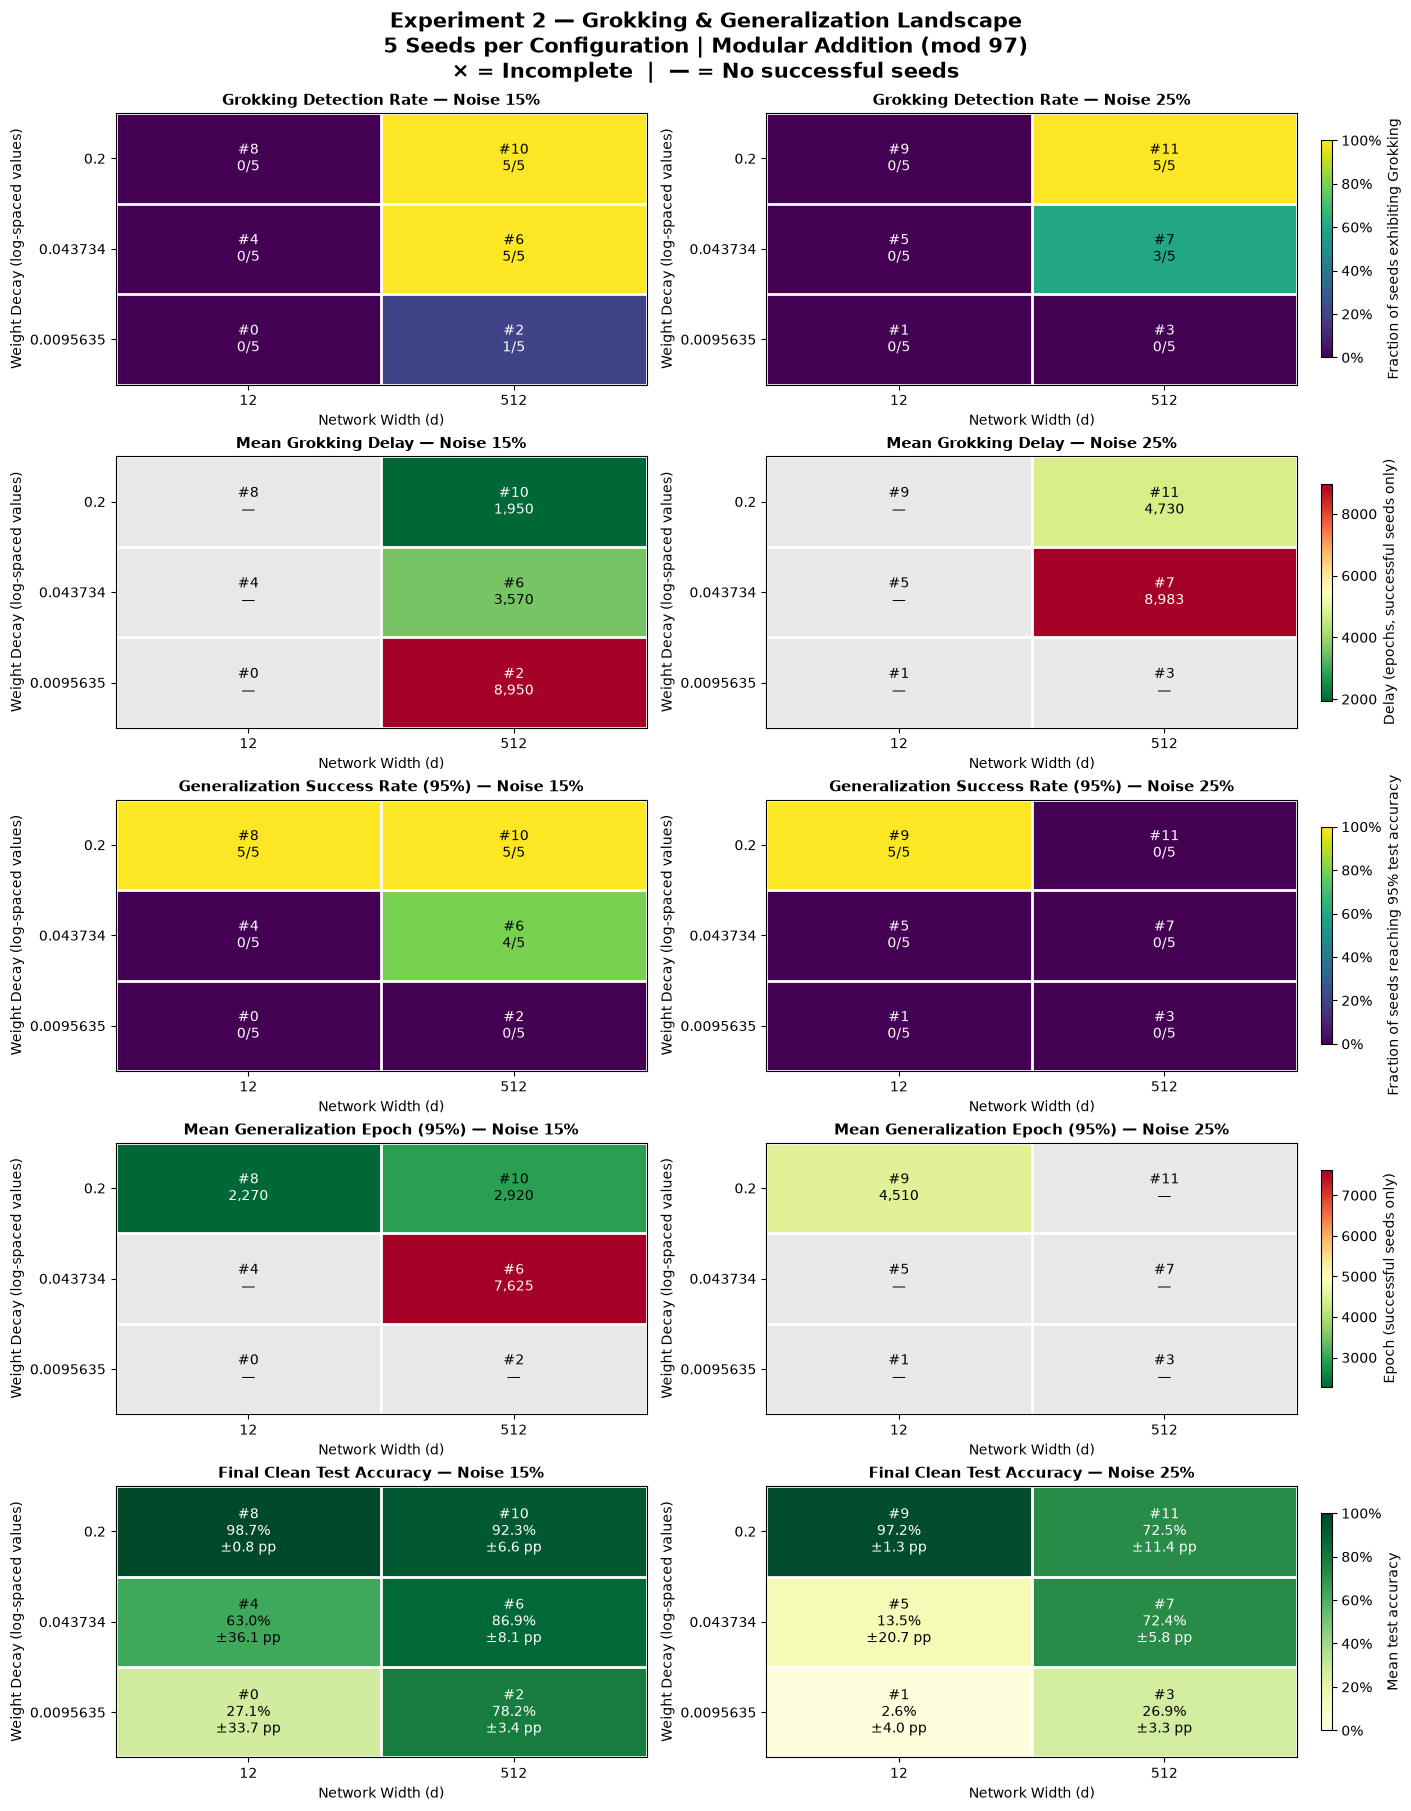

In [11]:
# ============================================================
# EXPERIMENT 2 — GROKKING & GENERALIZATION LANDSCAPE
# ============================================================

from matplotlib.colors import Normalize
from matplotlib.ticker import PercentFormatter


def plot_grokking_landscape(show=True, save=True):

    # ========================================================
    # 1. LOAD EXPERIMENT DATA
    # ========================================================

    results_path = OUT_DIR / "results.csv"

    if not results_path.exists():
        raise FileNotFoundError(
            f"{results_path} not found. "
            "Complete at least one configuration first."
        )

    with open(CONFIG_FILE, "r") as f:
        configurations = json.load(f)

    results = pd.read_csv(results_path)

    required_columns = {
        "index",
        "hiddenWidth",
        "weightDecay",
        "labelNoise",
        "numSeeds",
        "grokkingCount",
        "grokkingRate",
        "grokkingDelayMean",
        "generalizationCount",
        "generalizationRate",
        "generalizationEpochMean",
        "finalTestAccuracyMean",
        "finalTestAccuracyStd"
    }

    missing = required_columns - set(results.columns)

    if missing:
        raise ValueError(
            f"Missing results columns: {sorted(missing)}"
        )

    # ========================================================
    # 2. VALIDATE RESULTS
    # ========================================================

    configs_by_index = {
        int(config["index"]): config
        for config in configurations
    }

    if len(configs_by_index) != len(configurations):
        raise ValueError(
            "Duplicate configuration indices detected."
        )

    if results["index"].duplicated().any():
        raise ValueError(
            "Duplicate model indices in results.csv."
        )

    results_by_index = {}

    for _, row in results.iterrows():

        index = int(row["index"])

        if index not in configs_by_index:
            raise ValueError(
                f"Unknown model index: {index}"
            )

        config = configs_by_index[index]

        if (
            int(row["hiddenWidth"]) != config["hiddenWidth"]
            or int(row["labelNoise"]) != config["labelNoise"]
            or not np.isclose(
                float(row["weightDecay"]),
                config["weightDecay"],
                rtol=1e-8,
                atol=1e-12
            )
        ):
            raise ValueError(
                f"Model {index:03d}: configuration mismatch."
            )

        if int(row["numSeeds"]) != len(MODEL_SEEDS):
            raise ValueError(
                f"Model {index:03d}: seed count mismatch."
            )

        results_by_index[index] = row

    # ========================================================
    # 3. PREPARE AXES
    # ========================================================

    widths = sorted({
        int(config["hiddenWidth"])
        for config in configurations
    })

    weight_decays = sorted({
        float(config["weightDecay"])
        for config in configurations
    })

    noise_levels = sorted({
        int(config["labelNoise"])
        for config in configurations
    })

    width_positions = {
        width: i
        for i, width in enumerate(widths)
    }

    wd_positions = {
        wd: i
        for i, wd in enumerate(weight_decays)
    }

    # ========================================================
    # 4. DEFINE METRICS
    # ========================================================

    metrics = [
        {
            "column": "grokkingRate",
            "title": "Grokking Detection Rate",
            "colorbar": "Fraction of seeds exhibiting Grokking",
            "cmap": "viridis",
            "scale": "percentage"
        },
        {
            "column": "grokkingDelayMean",
            "title": "Mean Grokking Delay",
            "colorbar": "Delay (epochs, successful seeds only)",
            "cmap": "RdYlGn_r",
            "scale": "time"
        },
        {
            "column": "generalizationRate",
            "title": "Generalization Success Rate (95%)",
            "colorbar": "Fraction of seeds reaching 95% test accuracy",
            "cmap": "viridis",
            "scale": "percentage"
        },
        {
            "column": "generalizationEpochMean",
            "title": "Mean Generalization Epoch (95%)",
            "colorbar": "Epoch (successful seeds only)",
            "cmap": "RdYlGn_r",
            "scale": "time"
        },
        {
            "column": "finalTestAccuracyMean",
            "title": "Final Clean Test Accuracy",
            "colorbar": "Mean test accuracy",
            "cmap": "YlGn",
            "scale": "percentage"
        }
    ]

    # ========================================================
    # 5. CREATE FIGURE
    # ========================================================

    nrows = len(metrics)
    ncols = len(noise_levels)

    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(7 * ncols, 3.6 * nrows),
        squeeze=False,
        constrained_layout=True
    )

    fig.suptitle(
        "Experiment 2 — Grokking & Generalization Landscape\n"
        f"{len(MODEL_SEEDS)} Seeds per Configuration | "
        "Modular Addition (mod 97)\n"
        "× = Incomplete  |  "
        "— = No successful seeds",
        fontsize=15,
        fontweight="bold"
    )

    # ========================================================
    # 6. PLOT ALL METRICS
    # ========================================================

    for metric_index, metric in enumerate(metrics):

        column = metric["column"]

        # ----------------------------------------------------
        # SHARED COLOR SCALE ACROSS NOISE LEVELS
        # ----------------------------------------------------

        valid_values = pd.to_numeric(
            results[column],
            errors="coerce"
        ).to_numpy(dtype=float)

        valid_values = valid_values[
            np.isfinite(valid_values)
        ]

        if metric["scale"] == "percentage":

            norm = Normalize(
                vmin=0,
                vmax=1
            )

        elif len(valid_values) > 0:

            minimum = float(valid_values.min())
            maximum = float(valid_values.max())

            if minimum == maximum:
                minimum = max(0, minimum - 1)
                maximum += 1

            norm = Normalize(
                vmin=minimum,
                vmax=maximum
            )

        else:

            norm = Normalize(
                vmin=0,
                vmax=EPOCHS
            )

        cmap = plt.get_cmap(
            metric["cmap"]
        ).copy()

        # Gray indicates unavailable values
        cmap.set_bad("#E8E8E8")

        # ----------------------------------------------------
        # PLOT EACH NOISE LEVEL
        # ----------------------------------------------------

        for noise_index, noise in enumerate(noise_levels):

            ax = axes[metric_index, noise_index]

            values = np.full(
                (len(weight_decays), len(widths)),
                np.nan
            )

            annotations = {}

            # -----------------------------------------------
            # BUILD GRID FROM EXPECTED CONFIGURATIONS
            # -----------------------------------------------

            for config in configurations:

                if int(config["labelNoise"]) != noise:
                    continue

                index = int(config["index"])

                row_index = wd_positions[
                    float(config["weightDecay"])
                ]

                col_index = width_positions[
                    int(config["hiddenWidth"])
                ]

                # Configuration not yet fully completed
                if index not in results_by_index:

                    annotations[(row_index, col_index)] = (
                        f"#{index}\n×"
                    )

                    continue

                result = results_by_index[index]

                value = result[column]

                if pd.notna(value):
                    values[row_index, col_index] = float(value)

                # -------------------------------------------
                # FORMAT CELL ANNOTATION
                # -------------------------------------------

                if column == "grokkingRate":

                    label = (
                        f"{int(result['grokkingCount'])}"
                        f"/{int(result['numSeeds'])}"
                    )

                elif column == "generalizationRate":

                    label = (
                        f"{int(result['generalizationCount'])}"
                        f"/{int(result['numSeeds'])}"
                    )

                elif column == "finalTestAccuracyMean":

                    mean = float(
                        result["finalTestAccuracyMean"]
                    )

                    std = float(
                        result["finalTestAccuracyStd"]
                    )

                    if np.isfinite(std):
                        label = (
                            f"{mean:.1%}\n"
                            f"±{std * 100:.1f} pp"
                        )
                    else:
                        label = f"{mean:.1%}"

                elif pd.notna(value):

                    label = f"{float(value):,.0f}"

                else:

                    # No seeds reached the required criterion
                    label = "—"

                annotations[(row_index, col_index)] = (
                    f"#{index}\n{label}"
                )

            # -----------------------------------------------
            # DRAW HEATMAP
            # -----------------------------------------------

            image = ax.imshow(
                values,
                origin="lower",
                aspect="auto",
                interpolation="nearest",
                cmap=cmap,
                norm=norm
            )

            # -----------------------------------------------
            # ADD CELL LABELS
            # -----------------------------------------------

            for (row_index, col_index), label in annotations.items():

                value = values[row_index, col_index]

                # Choose readable text color
                if np.isfinite(value):

                    rgba = cmap(norm(value))

                    brightness = (
                        0.2126 * rgba[0]
                        + 0.7152 * rgba[1]
                        + 0.0722 * rgba[2]
                    )

                    text_color = (
                        "white"
                        if brightness < 0.45
                        else "black"
                    )

                else:
                    text_color = "black"

                ax.text(
                    col_index,
                    row_index,
                    label,
                    ha="center",
                    va="center",
                    fontsize=10,
                    fontweight="medium",
                    color=text_color
                )

            # -----------------------------------------------
            # AXES
            # -----------------------------------------------

            ax.set_title(
                f"{metric['title']} — Noise {noise}%",
                fontsize=11,
                fontweight="bold"
            )

            ax.set_xticks(
                range(len(widths))
            )

            ax.set_xticklabels(
                [str(width) for width in widths]
            )

            ax.set_yticks(
                range(len(weight_decays))
            )

            ax.set_yticklabels([
                f"{wd:.5g}"
                for wd in weight_decays
            ])

            ax.set_xlabel("Network Width (d)")
            ax.set_ylabel("Weight Decay (log-spaced values)")

            # Cell boundaries
            ax.set_xticks(
                np.arange(-0.5, len(widths), 1),
                minor=True
            )

            ax.set_yticks(
                np.arange(-0.5, len(weight_decays), 1),
                minor=True
            )

            ax.grid(
                which="minor",
                color="white",
                linewidth=2
            )

            ax.tick_params(
                which="minor",
                bottom=False,
                left=False
            )

        # ----------------------------------------------------
        # SHARED COLORBAR FOR THIS METRIC
        # ----------------------------------------------------

        # Skip time-based colorbars when no valid values exist
        has_values = (
            len(valid_values) > 0
        )

        if has_values or metric["scale"] == "percentage":

            colorbar = fig.colorbar(
                image,
                ax=axes[metric_index, :].tolist(),
                shrink=0.8,
                pad=0.02
            )

            colorbar.set_label(
                metric["colorbar"]
            )

            if metric["scale"] == "percentage":

                colorbar.ax.yaxis.set_major_formatter(
                    PercentFormatter(1.0)
                )

    # ========================================================
    # 7. SAVE FIGURE
    # ========================================================

    if save:

        plot_path = (
            OUT_DIR / "grokking_landscape.png"
        )

        fig.savefig(
            plot_path,
            dpi=170,
            bbox_inches="tight"
        )

        print(f"Saved: {plot_path}")

    # ========================================================
    # 8. EXPERIMENT SUMMARY
    # ========================================================

    completed = len(results)
    pending = len(configurations) - completed

    total_seeds = int(
        results["numSeeds"].sum()
    )

    grokking_count = int(
        results["grokkingCount"].sum()
    )

    generalization_count = int(
        results["generalizationCount"].sum()
    )

    print("\n" + "=" * 60)
    print("EXPERIMENT 2 — LANDSCAPE SUMMARY")
    print("=" * 60)

    print(
        f"Completed configurations: "
        f"{completed}/{len(configurations)}"
    )

    print(f"Incomplete configurations: {pending}")

    print(
        f"Grokking detected: "
        f"{grokking_count}/{total_seeds} completed seed runs"
    )

    print(
        f"Reached 95% generalization: "
        f"{generalization_count}/{total_seeds} "
        "completed seed runs"
    )

    # ========================================================
    # 9. DISPLAY OR CLOSE
    # ========================================================

    if show:
        plt.show()
    else:
        plt.close(fig)


# ============================================================
# GENERATE LANDSCAPE
# ============================================================

plot_grokking_landscape()
